# India Climate & Energy Atlas
## A reproducible exploration of development and the energy transition

**Data source:** World Bank Indicators API (live retrieval).  
**Countries:** India, Bangladesh, China, Indonesia, Sri Lanka and Vietnam.  
**Research focus:** GDP per capita, electricity access, renewable energy consumption, CO₂ emissions, population and electricity consumption.

This notebook uses real observations returned by the API. It does not create synthetic data. **Enable Internet in the notebook environment** so the API requests can run. If Internet is unavailable, the notebook stops with an explanatory error rather than silently substituting fabricated values.

**Important:** This is observational, country-level analysis. Correlations are not causal effects. Indicator coverage and publication lags differ by series.

## 1. Retrieve the real data

In [1]:
import json
import time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import display

BASE_URL = "https://api.worldbank.org/v2"
START_YEAR, END_YEAR = 2000, 2023
COUNTRIES = {
    "IND": "India", "BGD": "Bangladesh", "CHN": "China",
    "IDN": "Indonesia", "LKA": "Sri Lanka", "VNM": "Vietnam"
}
INDICATORS = {
    "NY.GDP.PCAP.KD": "GDP per capita (constant 2015 US$)",
    "EN.GHG.CO2.MT.CE.AR5": "CO2 emissions (metric tons)",
    "EG.ELC.ACCS.ZS": "Access to electricity (% of population)",
    "EG.FEC.RNEW.ZS": "Renewable energy consumption (% of total final energy consumption)",
    "SP.POP.TOTL": "Population, total",
    "EG.USE.ELEC.KH.PC": "Electric power consumption (kWh per capita)"
}

def fetch_indicator(indicator, retries=3):
    country_path = ";".join(COUNTRIES)
    url = f"{BASE_URL}/country/{country_path}/indicator/{indicator}"
    params = {"date": f"{START_YEAR}:{END_YEAR}", "format": "json", "per_page": 20000}
    last_error = None
    for attempt in range(retries):
        try:
            response = requests.get(url, params=params, timeout=45)
            response.raise_for_status()
            payload = response.json()
            if not isinstance(payload, list) or len(payload) < 2 or not payload[1]:
                return pd.DataFrame(columns=["country_code", "country", "year", "indicator_code", "indicator", "value"])
            rows = []
            for item in payload[1]:
                rows.append({
                    "country_code": item.get("countryiso3code"),
                    "country": (item.get("country") or {}).get("value"),
                    "year": int(item["date"]),
                    "indicator_code": indicator,
                    "indicator": INDICATORS[indicator],
                    "value": item.get("value")
                })
            return pd.DataFrame(rows)
        except Exception as exc:
            last_error = exc
            if attempt < retries - 1:
                time.sleep(1.5 * (attempt + 1))
    raise RuntimeError(f"Could not retrieve {indicator}: {last_error}") from last_error

try:
    long_data = pd.concat([fetch_indicator(code) for code in INDICATORS], ignore_index=True)
except Exception as exc:
    raise RuntimeError(
        "Live World Bank data could not be downloaded. Enable Internet for this notebook and rerun. "
        "No synthetic fallback is used."
    ) from exc

if long_data.empty:
    raise RuntimeError("The API returned no rows. Check the API and rerun later.")

long_data["value"] = pd.to_numeric(long_data["value"], errors="coerce")
data = long_data.pivot_table(
    index=["country_code", "country", "year"],
    columns="indicator_code", values="value", aggfunc="first"
).reset_index()
data.columns.name = None
data = data.rename(columns=INDICATORS).sort_values(["country_code", "year"]).reset_index(drop=True)
data = data.drop_duplicates(["country_code", "year"])
data.columns = [str(c).strip() for c in data.columns]
print("Available columns:", data.columns.tolist())
print(f"Retrieved {len(data):,} country-year rows for {data.country_code.nunique()} countries.")
print(f"Observed year range: {int(data.year.min())}–{int(data.year.max())}")
print("Retrieved at UTC:", datetime.now(timezone.utc).isoformat())
display(data.head())

Available columns: ['country_code', 'country', 'year', 'Access to electricity (% of population)', 'Renewable energy consumption (% of total final energy consumption)', 'Electric power consumption (kWh per capita)', 'CO2 emissions (metric tons)', 'GDP per capita (constant 2015 US$)', 'Population, total']
Retrieved 144 country-year rows for 6 countries.
Observed year range: 2000–2023
Retrieved at UTC: 2026-10-10T17:22:35.853149+00:00


,country_code,country,year,Access to electricity (% of population),Renewable energy consumption (% of total final energy consumption),Electric power consumption (kWh per capita),CO2 emissions (metric tons),GDP per capita (constant 2015 US$),"Population, total"
0,BGD,Bangladesh,2000,32.0,60.2,99.253551,26.9773,620.560473,134544304.0
1,BGD,Bangladesh,2001,35.0,55.9,109.490964,32.6330,641.288923,136805810.0
2,BGD,Bangladesh,2002,37.8,54.4,117.271799,34.3448,655.672139,138933658.0
3,BGD,Bangladesh,2003,40.5,52.6,123.721051,35.9887,676.826252,140970351.0
4,BGD,Bangladesh,2004,40.6,52.0,158.478288,37.9102,702.656357,142902856.0


## 2. Audit coverage and missingness

,indicator,non_missing,missing,coverage_pct
0,Access to electricity (% of population),144,0,100.00
2,Electric power consumption (kWh per capita),144,0,100.00
4,GDP per capita (constant 2015 US$),144,0,100.00
3,CO2 emissions (metric tons),144,0,100.00
5,"Population, total",144,0,100.00
1,Renewable energy consumption (% of total final...,132,12,91.67


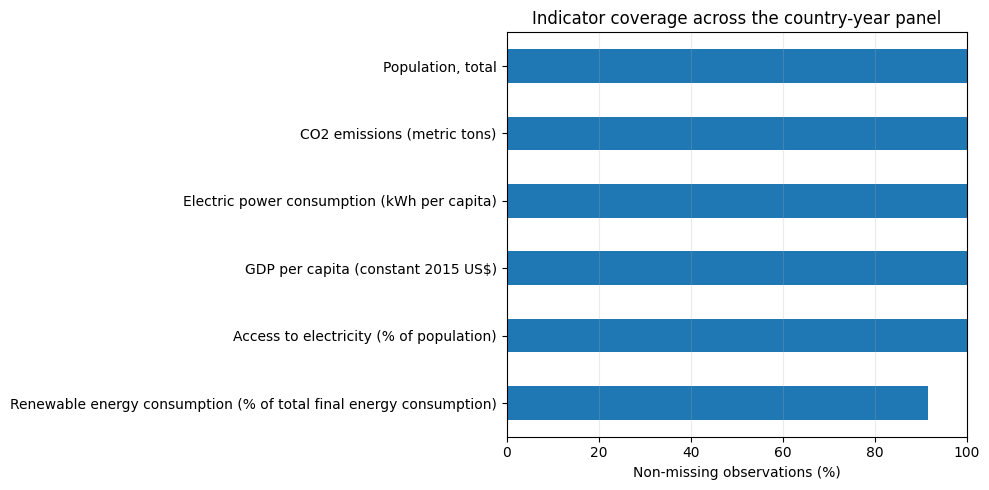

Missing values remain missing; they are never silently replaced with zero.


In [2]:
identifier_cols = {"country_code", "country", "year"}
metric_cols = [c for c in data.columns if c not in identifier_cols]
coverage = pd.DataFrame([
    {
        "indicator": col,
        "non_missing": int(data[col].notna().sum()),
        "missing": int(data[col].isna().sum()),
        "coverage_pct": round(float(data[col].notna().mean() * 100), 2)
    }
    for col in metric_cols
]).sort_values("coverage_pct", ascending=False)
display(coverage)
ax = coverage.sort_values("coverage_pct").plot(
    kind="barh", x="indicator", y="coverage_pct", legend=False, figsize=(10, 5),
    title="Indicator coverage across the country-year panel"
)
ax.set_xlabel("Non-missing observations (%)")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.grid(axis="x", alpha=.25)
plt.tight_layout()
plt.show()
print("Missing values remain missing; they are never silently replaced with zero.")

## 3. India trends

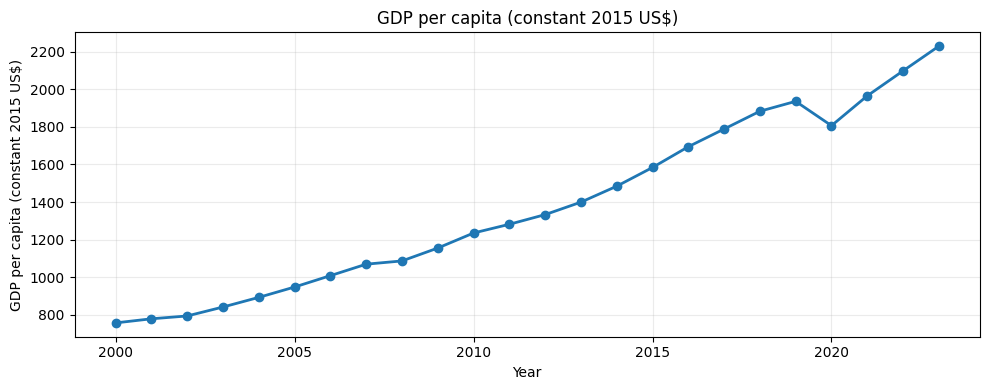

Not enough observed data for: CO2 emissions (metric tons per capita)


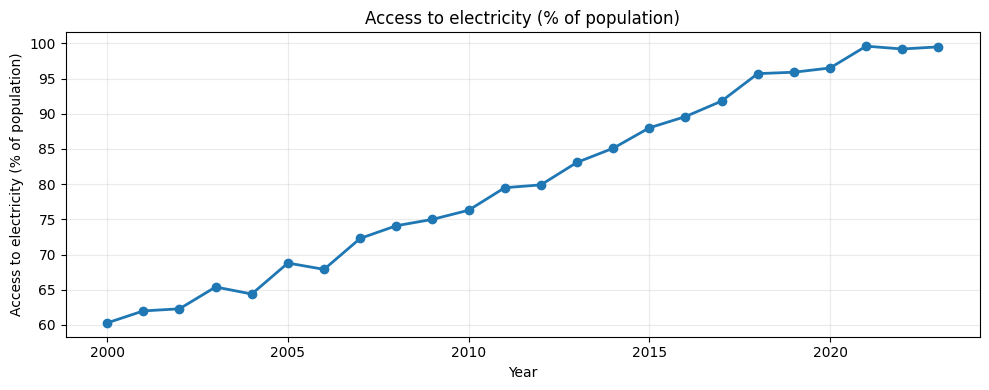

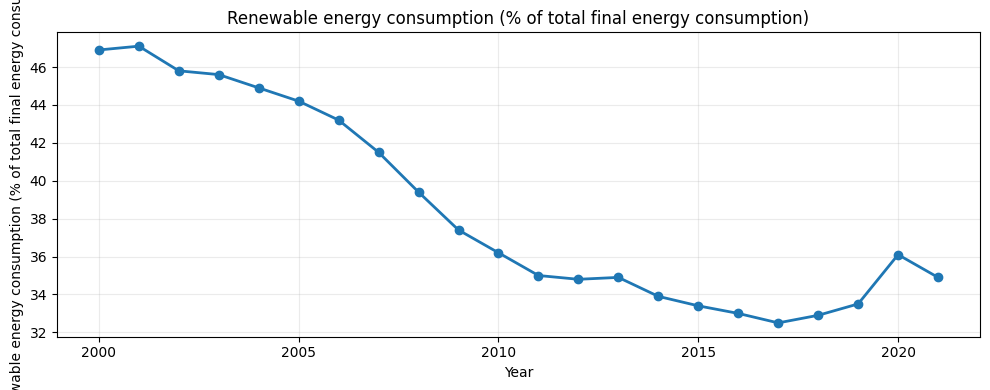

In [3]:
GDP = "GDP per capita (constant 2015 US$)"
CO2 = "CO2 emissions (metric tons per capita)"
ELECTRICITY = "Access to electricity (% of population)"
RENEWABLES = "Renewable energy consumption (% of total final energy consumption)"
core_metrics = [GDP, CO2, ELECTRICITY, RENEWABLES]
india = data[data.country_code == "IND"].sort_values("year").copy()

for metric in core_metrics:
    if metric in india.columns and india[metric].notna().sum() >= 2:
        observed = india[["year", metric]].dropna()
        fig, ax = plt.subplots(figsize=(10, 4))
        ax.plot(observed.year, observed[metric], marker="o", linewidth=2)
        ax.set_title(metric)
        ax.set_xlabel("Year")
        ax.set_ylabel(metric)
        ax.grid(True, alpha=.25)
        plt.tight_layout()
        plt.show()
    else:
        print("Not enough observed data for:", metric)

## 4. Endpoint changes with actual observation years

In [4]:
trend_rows = []
for metric in core_metrics:
    if metric not in india.columns:
        continue
    obs = india[["year", metric]].dropna().sort_values("year")
    if obs.empty:
        continue
    first, last = obs.iloc[0], obs.iloc[-1]
    pct = ((last[metric] / first[metric]) - 1) * 100 if first[metric] != 0 else np.nan
    trend_rows.append({
        "indicator": metric,
        "first_year": int(first.year), "first_value": float(first[metric]),
        "last_year": int(last.year), "last_value": float(last[metric]),
        "endpoint_change_pct": float(pct) if pd.notna(pct) else None,
        "observations": int(len(obs))
    })
trend_table = pd.DataFrame(trend_rows)
display(trend_table)
print("Endpoint change compares first and last observed values, which may span different years by indicator.")

,indicator,first_year,first_value,last_year,last_value,endpoint_change_pct,observations
0,GDP per capita (constant 2015 US$),2000,756.70411,2023,2229.714912,194.661399,24
1,Access to electricity (% of population),2000,60.30000,2023,99.500000,65.008292,24
2,Renewable energy consumption (% of total final...,2000,46.90000,2021,34.900000,-25.586354,22


Endpoint change compares first and last observed values, which may span different years by indicator.


## 5. GDP and CO₂: complete-pair sensitivity check

In [5]:

CO2 = "CO2 emissions (metric tons per capita)"
GDP = "GDP per capita (constant 2015 US$)"

# Find the actual CO2 column name, ignoring spaces/case
co2_col = next(
    (c for c in india.columns
     if "co2" in str(c).lower() or "carbon dioxide" in str(c).lower()),
    None
)

if co2_col is None:
    print("CO2 data is missing from the downloaded World Bank data.")
else:
    paired = india[["year", GDP, co2_col]].dropna().sort_values("year")
    print("CO2 column found:", co2_col)
    print("Complete years:", len(paired))
    if len(paired) >= 3:
        print("Correlation:", paired[GDP].corr(paired[co2_col]))
    else:
        print("Not enough complete years to calculate correlation.")


CO2 column found: CO2 emissions (metric tons)
Complete years: 24
Correlation: 0.9894243489562381


## 6. Country comparison over observed data

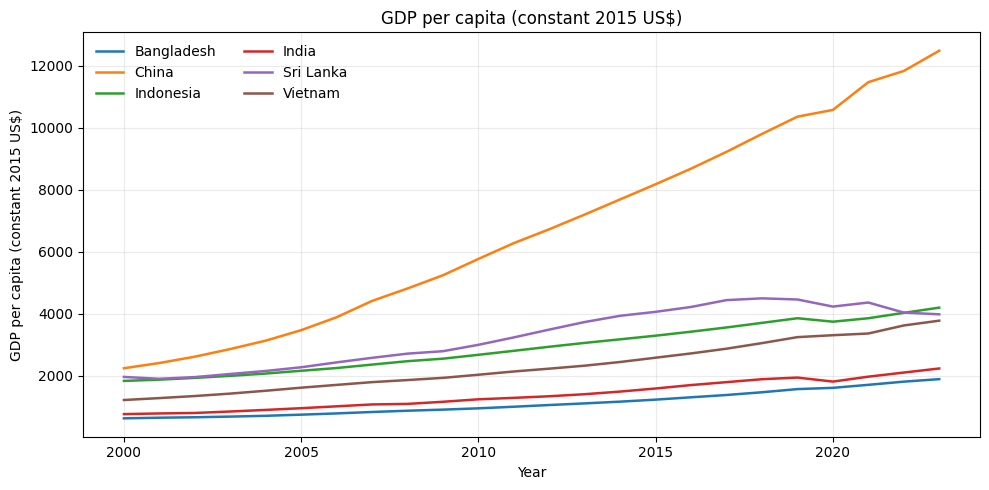

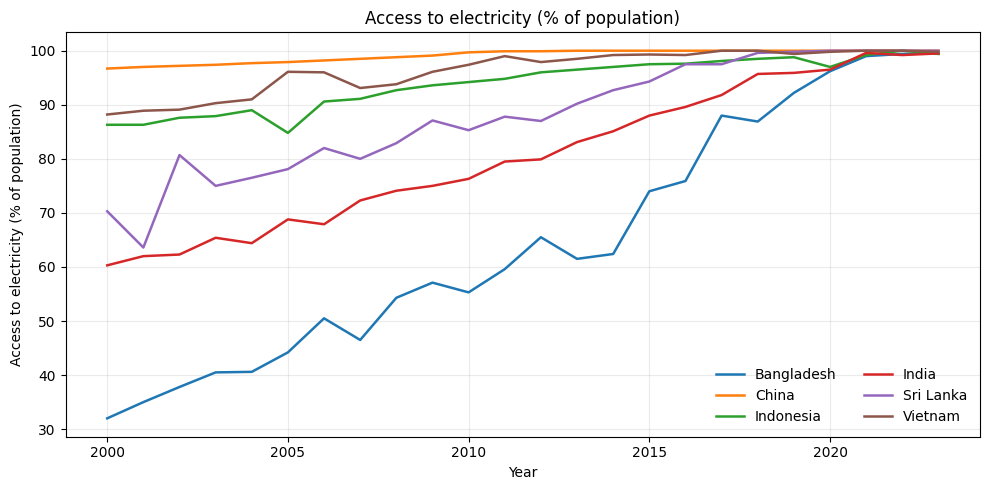

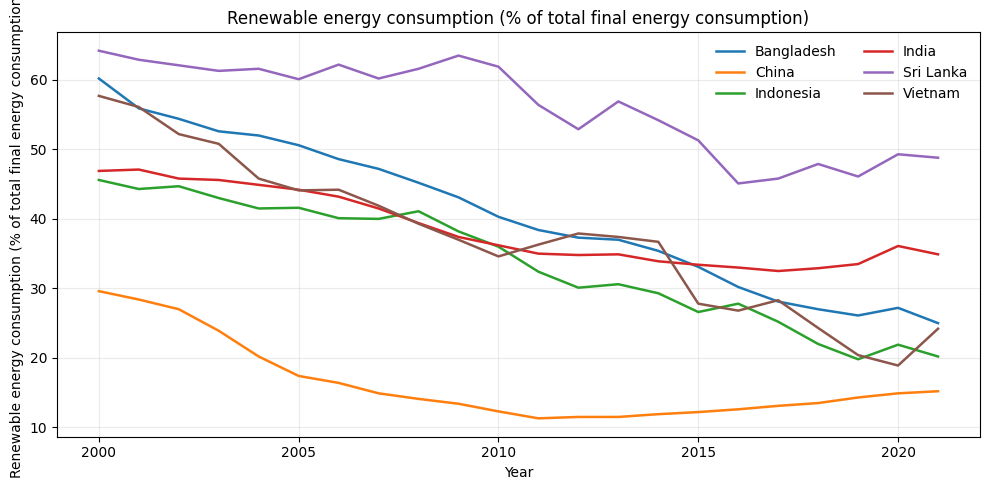

In [6]:
selected = data[data.country_code.isin(COUNTRIES)].copy()
for metric in [GDP, CO2, ELECTRICITY, RENEWABLES]:
    if metric not in selected.columns:
        continue
    fig, ax = plt.subplots(figsize=(10, 5))
    for code, group in selected.groupby("country_code"):
        obs = group[["year", metric]].dropna().sort_values("year")
        if not obs.empty:
            ax.plot(obs.year, obs[metric], label=COUNTRIES.get(code, code), linewidth=1.8)
    ax.set_title(metric)
    ax.set_xlabel("Year")
    ax.set_ylabel(metric)
    ax.legend(ncol=2, frameon=False)
    ax.grid(True, alpha=.25)
    plt.tight_layout()
    plt.show()

if GDP in selected and CO2 in selected:
    display(selected.dropna(subset=[GDP, CO2]).groupby(["country_code", "country"]).agg(
        first_year=("year", "min"),
        last_year=("year", "max"),
        complete_years=("year", "size"),
        mean_gdp_per_capita=(GDP, "mean"),
        mean_co2_per_capita=(CO2, "mean")
    ).reset_index())

## 7. Export reproducible artifacts

In [7]:
OUT = Path("earth_atlas_outputs")
OUT.mkdir(exist_ok=True)
data.to_csv(OUT / "world_bank_panel.csv", index=False)
coverage.to_csv(OUT / "coverage.csv", index=False)
metadata = {
    "source": "World Bank Indicators API",
    "source_url": BASE_URL,
    "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
    "start_year": START_YEAR,
    "end_year": END_YEAR,
    "countries": COUNTRIES,
    "indicators": INDICATORS,
    "rows": int(len(data)),
    "missing_values_preserved": True,
    "interpretation_note": "Descriptive analysis only; correlations do not establish causation."
}
(OUT / "data_provenance.json").write_text(json.dumps(metadata, indent=2))
print("Saved real panel, coverage table and provenance metadata to:", OUT.resolve())
display(data.tail())

Saved real panel, coverage table and provenance metadata to: /kaggle/working/earth_atlas_outputs


,country_code,country,year,Access to electricity (% of population),Renewable energy consumption (% of total final energy consumption),Electric power consumption (kWh per capita),CO2 emissions (metric tons),GDP per capita (constant 2015 US$),"Population, total"
139,VNM,Viet Nam,2019,99.4,20.4,2290.268107,336.5288,3241.076490,97173776.0
140,VNM,Viet Nam,2020,99.8,18.9,2312.253983,348.3315,3303.169498,98079191.0
141,VNM,Viet Nam,2021,100.0,24.2,2402.322379,336.1703,3358.217348,98935098.0
142,VNM,Viet Nam,2022,100.0,NaN,2490.884515,343.9999,3617.663113,99680655.0
143,VNM,Viet Nam,2023,99.8,NaN,2550.108721,390.7253,3772.360291,100352192.0


## 8. Limitations and publication checklist

- The dataset is a country-level observational panel; it cannot establish causal effects.
- Indicator definitions, sources, publication lags and historical revisions can differ.
- The World Bank electricity-access series may include modeled estimates; consult its metadata before interpreting changes.
- Renewable energy consumption is not the same as renewable electricity generation.
- Do not claim “emissions decoupling” from a simple correlation. Define the term, distinguish absolute from per-capita emissions and test sensitivity.
- Cite the World Bank API and record the retrieval date.
- Before publishing, restart the kernel and run every cell from top to bottom.
- Never claim a result or accuracy score that is not reproduced by the notebook.